### Popularity-based Product Recommendation System 

# Section - 1 (Importing The data)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("saurav9786/amazon-product-reviews")

In [3]:
#import the reqired libraries
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
import joblib 
import scipy.sparse
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
import warnings; warnings.simplefilter('ignore')

#Importing Surprise and relevant packages to do some hyper parameter tuning through Grid Search
from surprise import Dataset
from surprise import Reader
from surprise.model_selection import cross_validate
from surprise.model_selection import GridSearchCV
from surprise import KNNBasic, KNNWithMeans, KNNWithZScore
from surprise import SVD, SVDpp, NMF
from surprise import SlopeOne, CoClustering
# %matplotlib inline

In [4]:
path = path+"\\ratings_Electronics (1).csv"
columns = ['userId', 'productId', 'rating', 'timestamp']
dataset = pd.read_csv(path, names=columns, header=0)
dataset.head()

,userId,productId,rating,timestamp
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     str    
 1   productId  str    
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 238.8 MB


In [6]:
print('Number of missing values across columns: \n',dataset.isnull().sum())


Number of missing values across columns: 
 userId       0
productId    0
rating       0
timestamp    0
dtype: int64


In [7]:
#Checking the number of rows and columns
rows,columns=dataset.shape
print('Number of rows: ',rows)
print('Number of columns: ',columns)

Number of rows:  7824481
Number of columns:  4


##### So There are no missing records in the dataset

# Section-2 (Analyzing the Data)

array([[<Axes: title={'center': 'rating'}>,
        <Axes: title={'center': 'timestamp'}>]], dtype=object)

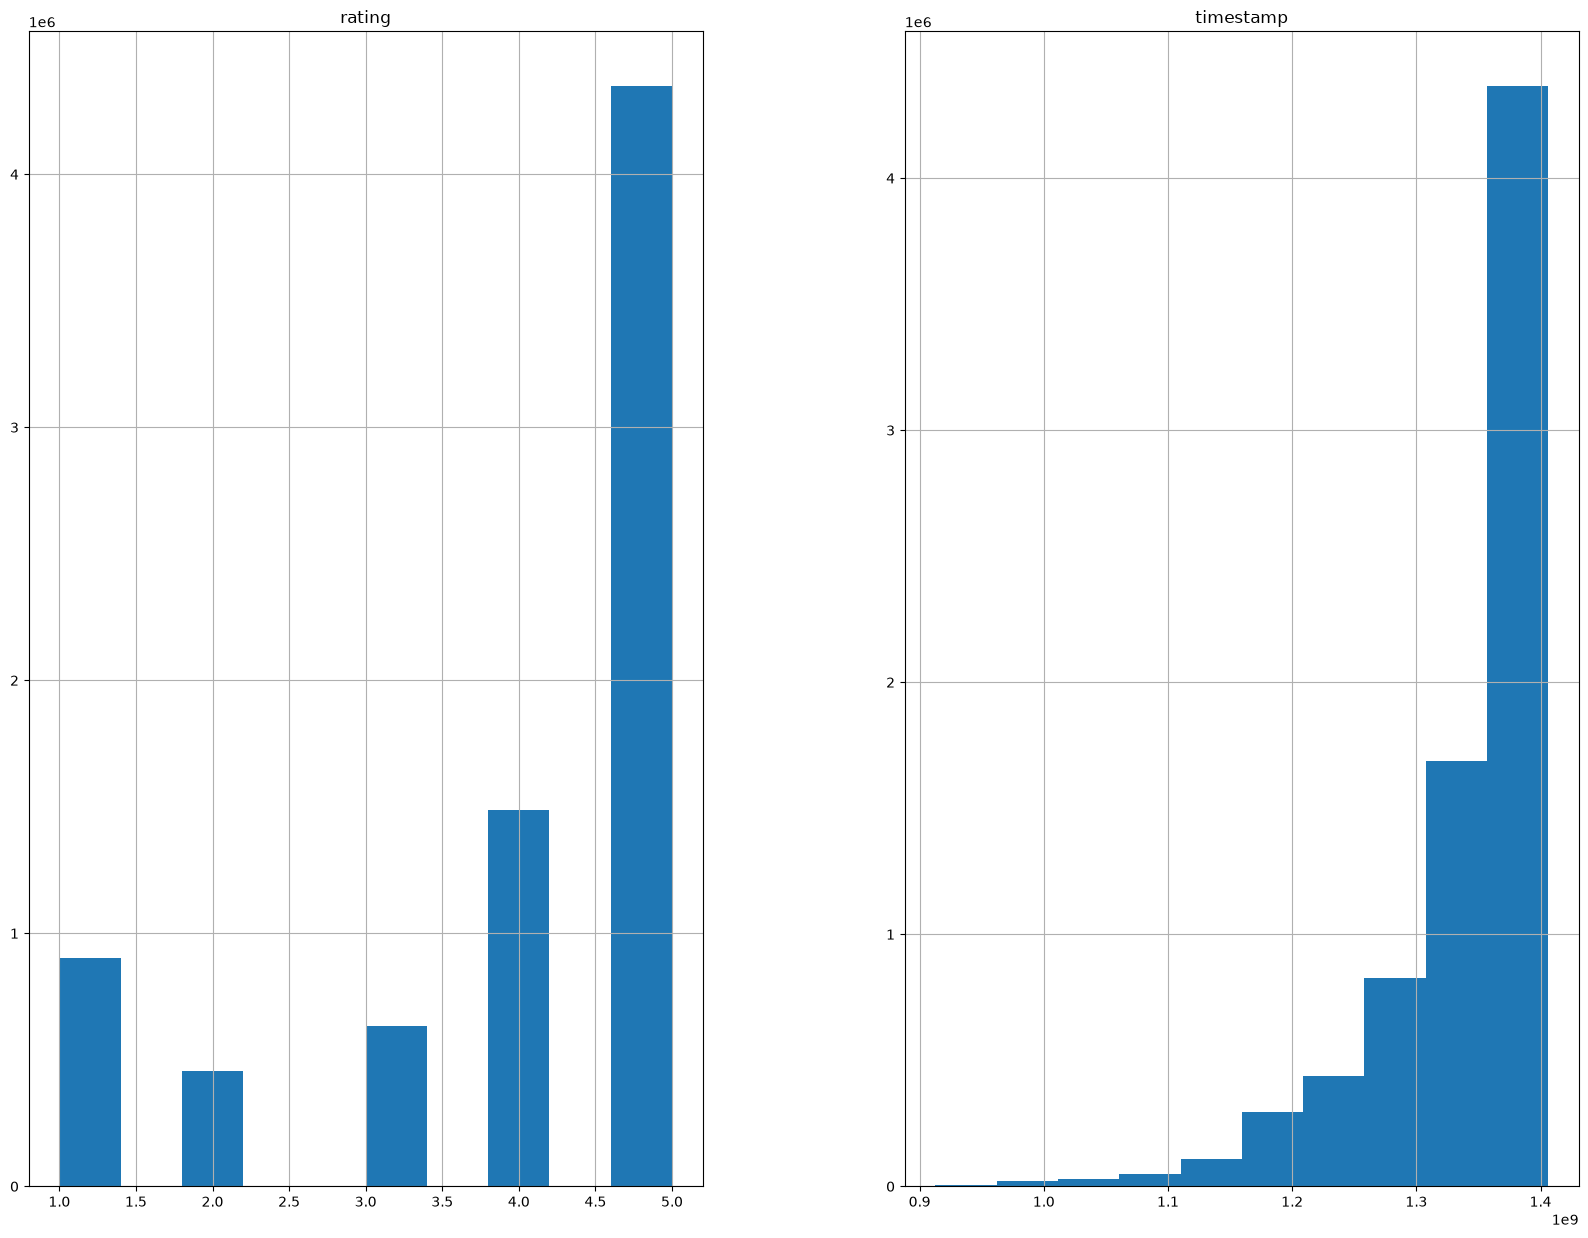

In [8]:
dataset.hist(figsize=(20, 15))
plt.show()

#### Removing the timestamp attribute as it is not required for our analysis

In [9]:
dataset.drop('timestamp',axis=1,inplace=True)

In [10]:
print("Electronic Data Summary")
print("="*100)
print("\nTotal # of Ratings :",dataset.shape[0])
print("Total # of Users   :", len(np.unique(dataset.userId)))
print("Total # of Products  :", len(np.unique(dataset.productId)))
print("\n")
print("="*100)

Electronic Data Summary

Total # of Ratings : 7824481
Total # of Users   : 4201696
Total # of Products  : 476001




### The Dataset is very Large with more no. of users than no. of products so lets consider a new dataset of a smaller size

In [11]:
datasubset = dataset.iloc()[:1000000, :]
datasubset.shape

(1000000, 3)

In [12]:
datasubset.head()

,userId,productId,rating
0,A2CX7LUOHB2NDG,0321732944,5.0
1,A2NWSAGRHCP8N5,0439886341,1.0
2,A2WNBOD3WNDNKT,0439886341,3.0
3,A1GI0U4ZRJA8WN,0439886341,1.0
4,A1QGNMC6O1VW39,0511189877,5.0


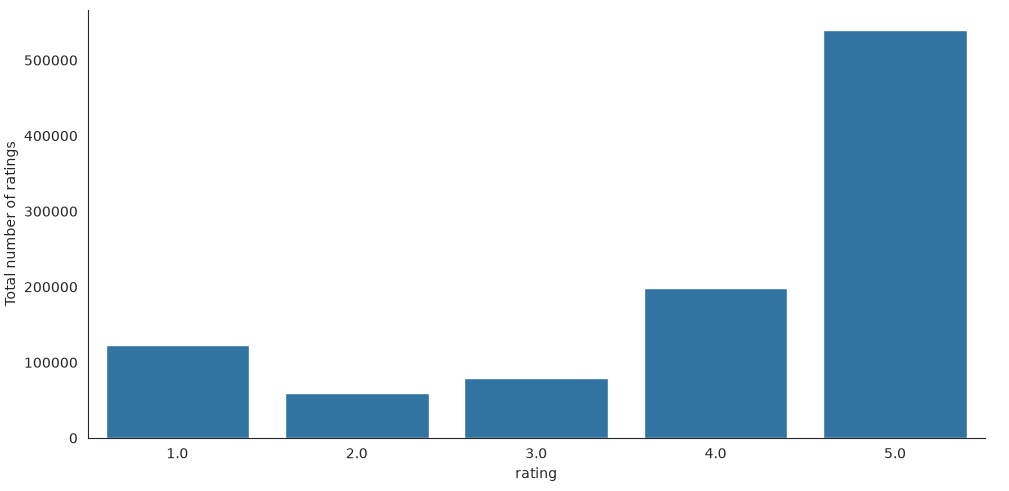

In [13]:
# Check the distribution of the rating
with sns.axes_style('white'):
    g = sns.catplot(x="rating", data=datasubset, aspect=2.0, kind='count')
    g.set_ylabels("Total number of ratings")


<Axes: ylabel='rating'>

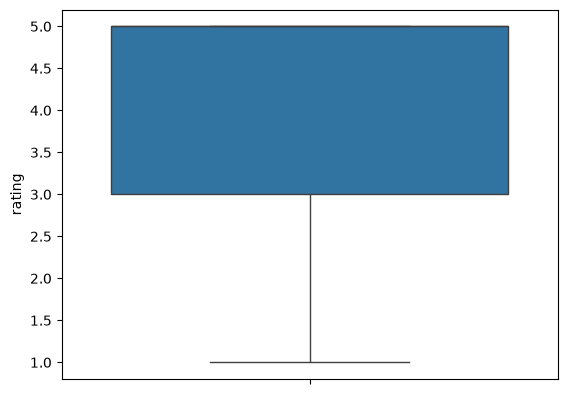

In [14]:
sns.boxplot(y='rating',data=datasubset)

### As we can see most of the ratings lie between 3 to 5

### Now lets check no. of products a customer has rated

In [15]:
datasubset.drop_duplicates(inplace=True)
most_rated=datasubset.groupby('userId').size().sort_values(ascending=False)
print('Users based on ratings: \n',most_rated)

Users based on ratings: 
 userId
A5JLAU2ARJ0BO           409
A231WM2Z2JL0U3          249
A25HBO5V8S8SEA          164
A6FIAB28IS79            138
AT6CZDCP4TRGA           125
                       ... 
AZZURKWE5L0EU             1
AZZUX6QT7M1IC             1
AZZV2NAQL8KHQ             1
AZZV891DC7X6Q             1
A000681618A3WRMCK53V      1
Length: 754152, dtype: int64


In [16]:
counts=datasubset.userId.value_counts()
datasubset_final=datasubset[datasubset.userId.isin(counts[counts>=10].index)]
print('Number of users who have rated 10 or more items =', len(datasubset_final))
print('Number of unique users in the final data = ', datasubset_final['userId'].nunique())
print('Number of unique products in the final data = ', datasubset_final['productId'].nunique())

Number of users who have rated 10 or more items = 34975
Number of unique users in the final data =  2176
Number of unique products in the final data =  15044


* datasubset_final has the users who have rated 10 or more items. Because users who haven't used much products shouldn't be accounted for.

In [17]:
#statistical analysis of the most rated user data
most_rated.describe().astype(int).T

count    754152
mean          1
std           1
min           1
25%           1
50%           1
75%           1
max         409
dtype: int64

Text(0.5, 1.0, '# RATINGS per Product')

Text(0.5, 0, 'Product')

Text(0, 0.5, '# ratings per product')

[Text(-2000.0, 0, ''),
 Text(0.0, 0, ''),
 Text(2000.0, 0, ''),
 Text(4000.0, 0, ''),
 Text(6000.0, 0, ''),
 Text(8000.0, 0, ''),
 Text(10000.0, 0, ''),
 Text(12000.0, 0, ''),
 Text(14000.0, 0, ''),
 Text(16000.0, 0, '')]

<function matplotlib.pyplot.show(close=None, block=None)>

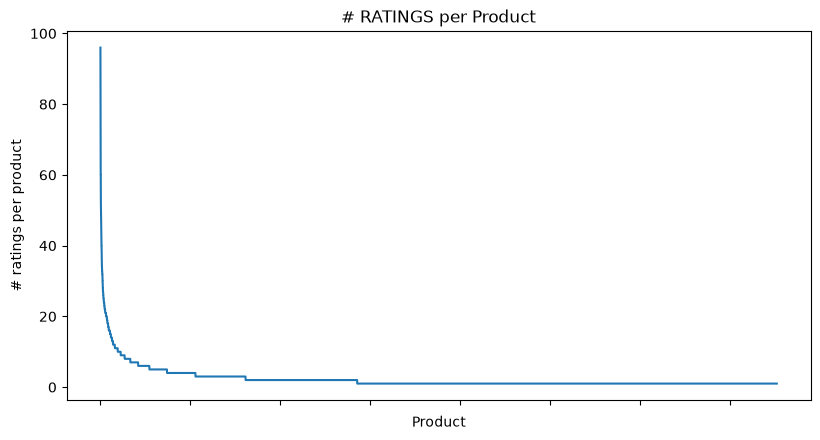

In [18]:
#Products also have skewed ratings with majority of the products having very few ratings
no_of_ratings_per_product = datasubset_final.groupby(by='productId')['rating'].count().sort_values(ascending=False)

fig = plt.figure(figsize=plt.figaspect(.5))
ax = plt.gca()
plt.plot(no_of_ratings_per_product.values)
plt.title('# RATINGS per Product')
plt.xlabel('Product')
plt.ylabel('# ratings per product')
ax.set_xticklabels([])

plt.show

In [19]:
ratings_mean_count = pd.DataFrame(datasubset_final.groupby('productId')['rating'].mean())
ratings_mean_count['rating_counts'] = pd.DataFrame(datasubset_final.groupby('productId')['rating'].count())
ratings_mean_count.head()




,rating,rating_counts
productId,,
0594481813,3.0,1
0970407998,4.0,1
0972683275,4.6,5
1400501466,4.0,4
1400501520,5.0,1


In [20]:
#The maximum number of ratings received for a product is 96

ratings_mean_count['rating_counts'].max()

np.int64(96)

<Figure size 800x600 with 0 Axes>

<Axes: >

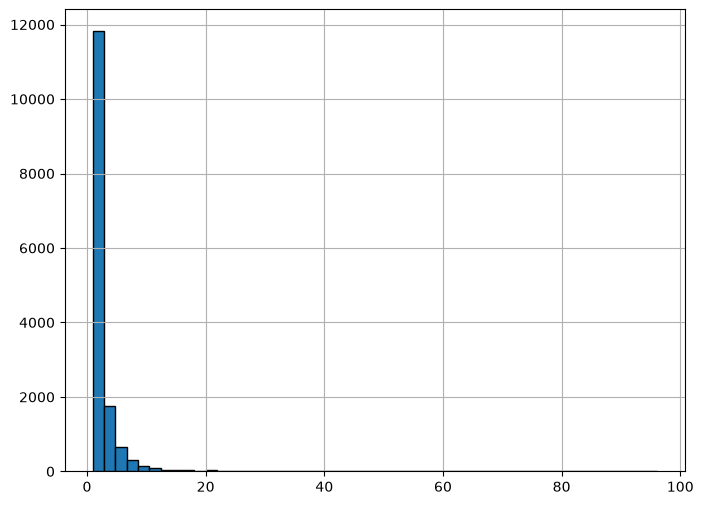

In [21]:
#### Majority of the products have received 1 rating only and it is a right skewed distribution
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
ratings_mean_count['rating_counts'].hist(bins=50)

<Figure size 800x600 with 0 Axes>

<Axes: >

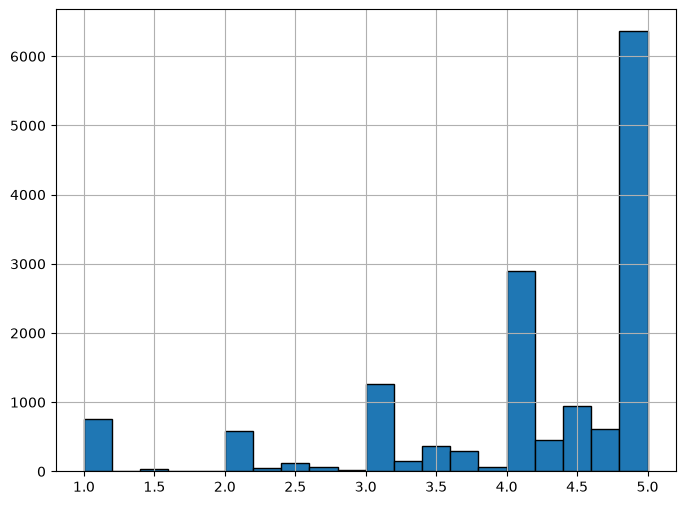

In [22]:
#We see a left skewed distribution for the ratings
#There are clusters at each of the points 1,2,3,4,5 as that is where the means are concentrated
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
ratings_mean_count['rating'].hist(bins=20)

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

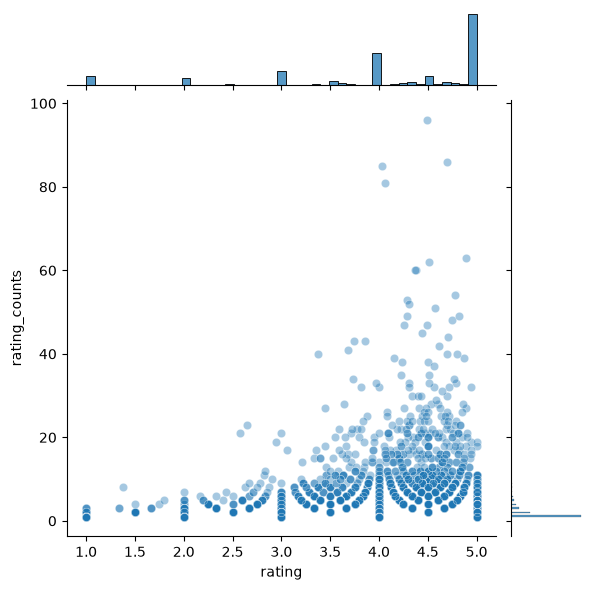

In [23]:
#From the joint plot below it seems that popular products (higher ratings) tend to be rated more frequently, majority have rated products in the higher range
#To make people more engaged (bottom of the chart) we can start by recommending them based on popularity based system and then
#slowly graduate them to collaborative system once we have sufficient number of data points to giver personlized recommendation
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
sns.jointplot(x='rating', y='rating_counts', data=ratings_mean_count, alpha=0.4)

<Axes: xlabel='productId'>

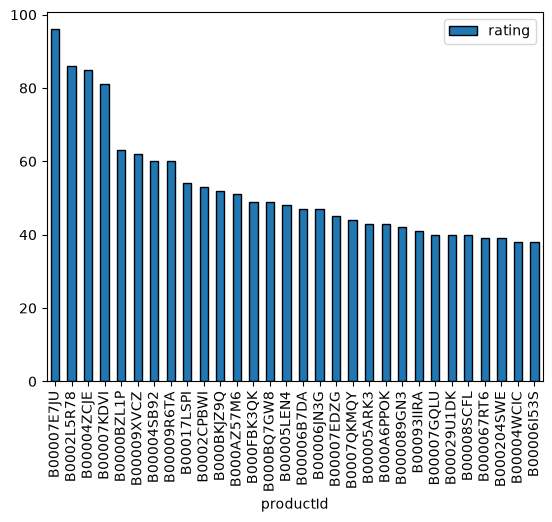

In [24]:
popular_products = pd.DataFrame(datasubset_final.groupby('productId')['rating'].count())
most_popular = popular_products.sort_values('rating', ascending=False)
most_popular.head(30).plot(kind = "bar")

In [25]:
no_of_ratings_per_user = datasubset_final.groupby(by='userId')['rating'].count().sort_values(ascending=False)

# Section - 3 (Contructing Pivot and Making The Model)

## 1. Constructing pivot table on `userId` and `productId` column based on the value of `ratings`


In [26]:
#constructing the pivot table
final_ratings_matrix = datasubset_final.pivot(index = 'userId', columns ='productId', values = 'rating').fillna(0)
final_ratings_matrix.head()

productId,0594481813,0970407998,0972683275,1400501466,1400501520,1400501776,1400532620,1400532655,140053271X,1400599997,...,B000HDKZ32,B000HDKZPU,B000HDL05O,B000HDMRNS,B000HDMUU8,B000HDONSK,B000HDONV2,B000HDONWQ,B000HDQ2G6,B000HDU0Q4
userId,,,,,,,,,,,,,,,,,,,,,
A100UD67AHFODS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A100WO06OQR8BQ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A101OAAMZYWQ3U,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A1053TBGTIEQ8V,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A105TOJ6LTVMBG,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


* It shows that it is a sparse matrix. So, many cells are filled with 0 values.

In [27]:
print('Shape of final_ratings_matrix: ', final_ratings_matrix.shape)

Shape of final_ratings_matrix:  (2176, 15044)


In [28]:
#Calucating the density of the rating marix
given_num_of_ratings = np.count_nonzero(final_ratings_matrix)
print('given_num_of_ratings = ', given_num_of_ratings)
possible_num_of_ratings = final_ratings_matrix.shape[0] * final_ratings_matrix.shape[1]
print('possible_num_of_ratings = ', possible_num_of_ratings)
density = (given_num_of_ratings/possible_num_of_ratings)
density *= 100
print ('density: {:4.2f}%'.format(density))

given_num_of_ratings =  34975
possible_num_of_ratings =  32735744
density: 0.11%


* The density value of the matrix also shows that it is a sparse matrix.

# 2. Splitting the data

In [34]:
#Split the data randomnly into train and test datasets into 70:30 ratio
train_data, test_data = train_test_split(datasubset_final, test_size = 0.3, random_state=42)
train_data.head()

,userId,productId,rating
705189,A2SH7OWE8QJYNC,B000A6NV0U,5.0
493869,A15XI2BEGGFEOW,B0002LEMWE,5.0
372704,A1IU7S4HCK1XK0,B0001A06GW,5.0
76052,A1MJMYLRTZ76ZX,B000050AOR,4.0
461577,A31N0XY2UTB25C,B0002ER2YQ,5.0


In [35]:
print('Shape of training data: ',train_data.shape)
print('Shape of testing data: ',test_data.shape)

Shape of training data:  (24482, 3)
Shape of testing data:  (10493, 3)


# 3. Building a Model that rates based on most bought products and average ratings

In [89]:
# Sample fuction to use manual popularity based recommender model to make predictions
def recommend(train_data, user_id):
    #Group the training data by productId and count the number of unique users who have rated each product. This will give us a score for each product based on its popularity.
    train_data_grouped = train_data.groupby('productId').agg({'userId': 'count'}).reset_index()
    train_data_grouped.rename(columns = {'userId': 'score'},inplace=True)

    #Get the sum of ratings for each product. This will give us the total rating for each product.
    product_summary = train_data.groupby('productId')['rating'].sum().reset_index()

    #Combine the two dataframes to get a final dataframe with productId, score, and total rating. Then calculate the average rating for each product by dividing the total rating by the score. Finally, sort the products by score in descending order to get the most popular products.
    train_data_sorted = pd.concat([train_data_grouped, product_summary[['rating']]], axis=1)
    train_data_sorted['rating'] = train_data_sorted['rating'] / train_data_sorted['score']
    train_data_sorted.rename(columns = {'rating': 'avg_rating'},inplace=True)
    train_data_sorted = train_data_sorted.sort_values(['score'], ascending = [0])

    #Get the top 50 recommendations based on score and then sort them by average rating in descending order to get the best rated products among the most popular ones.
    user_recommendations = train_data_sorted.head(50).sort_values(['avg_rating'], ascending = [0])
          
    #Add user_id column for which the recommendations are being generated 
    user_recommendations['userId'] = user_id 
      
    #Bring user_id column to the front 
    cols = user_recommendations.columns.tolist() 
    cols = cols[-1:] + cols[:-1] 
    user_recommendations = user_recommendations[cols] 
          
    return user_recommendations.head(10)

In [90]:
# Since, it is a Popularity recommender model, so, all the three users are given the same recommendations. Here, we predict the products based on the popularity. It is not personalized to particular user. It is a non-personalized recommender system.
find_recom = [10,100,150]   # This list is user choice.
for i in find_recom:
    print("The list of recommendations for the userId: %d\n" %(i))
    print(recommend(train_data, i))    
    print("\n") 

The list of recommendations for the userId: 10

      userId   productId  score  avg_rating
4204      10  B00009R6WO     22    4.909091
3428      10  B00007GQLU     29    4.896552
8184      10  B0007QKMQY     28    4.892857
3426      10  B00007GQLS     24    4.875000
2327      10  B000067RT6     27    4.851852
6440      10  B00029U1DK     25    4.840000
4928      10  B0000BZL1P     40    4.825000
1290      10  B000053HH5     26    4.730769
8522      10  B00081A2KY     22    4.727273
5581      10  B00017LSPI     40    4.725000


The list of recommendations for the userId: 100

      userId   productId  score  avg_rating
4204     100  B00009R6WO     22    4.909091
3428     100  B00007GQLU     29    4.896552
8184     100  B0007QKMQY     28    4.892857
3426     100  B00007GQLS     24    4.875000
2327     100  B000067RT6     27    4.851852
6440     100  B00029U1DK     25    4.840000
4928     100  B0000BZL1P     40    4.825000
1290     100  B000053HH5     26    4.730769
8522     100  B00081A

#### Evaluation of the manual popularity based model

In [104]:
# Calculate product averages using training data only
product_mean = train_data.groupby('productId')['rating'].mean()
global_mean = train_data['rating'].mean()

# Predict each test rating from that product's training average.
# Use the training-set global average for products not seen in training.
y_pred = test_data['productId'].map(product_mean).fillna(global_mean)
y_true = test_data['rating']

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

MSE:  1.6050
RMSE: 1.2669


# Final Thoughts

## 1. Existing Method: Average Rating-Based Recommendation

The current recommendation model recommends products based on their **average ratings given by other users**. It calculates the average rating of each product using the available user-rating data and recommends products with higher average ratings.

### How it works
1. Collect ratings given by different users to each product.
2. Group the data by `productId`.
3. Calculate the average rating for each product.
4. Rank products based on their average ratings.
5. Recommend products with higher average ratings to the user.

### Example

| Product | User Ratings | Average Rating |
|---|---|---:|
| Product A | 5, 4, 5 | 4.67 |
| Product B | 3, 4, 3 | 3.33 |
| Product C | 5, 5, 4 | 4.67 |

Products A and C receive higher rankings because they have higher average ratings.

### Limitation

This method considers the overall ratings of products rather than an individual user's interests. Consequently, different users may receive similar recommendations even if their preferences differ.

---

## 2. New Method: Preference Similarity-Based Recommendation

The new recommendation method aims to recommend products based on **similarity between users' preferences** rather than relying only on the average ratings of products.

It uses the ratings provided by users to identify patterns in their preferences and find products that are likely to interest a particular user.

### How it works
1. Construct a user-product rating matrix from the available rating data.
2. Identify similarities between users based on their rating patterns, or learn latent preference patterns using matrix factorization.
3. Estimate how much a target user may like products they have not rated.
4. Rank candidate products according to their predicted relevance to the target user.
5. Recommend the highest-ranked products.

### Example

Suppose User A and User B both give high ratings to action games and low ratings to puzzle games. If User B likes a particular action game that User A has not rated, the system may recommend that game to User A.

### Advantages
- Provides more personalized recommendations.
- Considers individual user preferences.
- Can identify products that may interest a user even when their overall average ratings are not the highest.

### Comparison

| Feature | Average Rating-Based Method | Preference Similarity-Based Method |
|---|---|---|
| Main basis | Average product ratings | Similarity between user preferences or learned preference patterns |
| Personalization | Limited | Higher |
| User-specific predictions | Not necessarily | Yes |
| Main objective | Recommend highly rated products | Recommend products relevant to the user |

**Conclusion:** The existing method provides a simple baseline by recommending products with high average ratings. The new method aims to improve personalization by considering individual preferences and predicting which products a particular user is likely to enjoy.
